# FBW2 tryptophans in AGO1 pockets: ABCfold ensemble (600 models, 6 engines)

This repeats [fbw2_ago1_trp_pockets.ipynb](fbw2_ago1_trp_pockets.ipynb) (5 ColabFold models) on the much larger
ABCfold ensemble `AGO1_modelling/ABCfold_ifb_AGO1_MiRs_complexes/results/ago1_fbw2/`: AlphaFold3, Boltz, Chai-1,
OpenFold3, Protenix and RoseTTAFold3, with 100 models each, grouped into pose clusters.

**Method** (unchanged; worker in [trp_pockets.py](trp_pockets.py)). pyKVFinder (Guerra *et al.* 2021) runs on
**apo AGO1**: FBW2 removed, AGO1 residues with pLDDT < 50 dropped, probe_out = 8 Å. A *global* pass finds the
cavity each Trp indole sits in. A *ligand-mode* pass per Trp (side chain as ligand, 5 Å) gives the sub-pocket's
volume, depth and lining residues. A "contact" means an AGO1 heavy atom within 4.5 Å of the indole **or** a PLIP
interaction (`all_selected_summary.csv`). CDD sites and domains come from the NanoPulldown annotation of O04379.

**Dataset notes**
* `minimized/` also holds 455 **stale** models from an earlier clustering, so only the 600 models of
  `selected_models.csv` (current clusters, ipTM) are used.
* The modelled AGO1 has **1,050 aa**: an `IR` insertion at 332–333 compared with UniProt O04379 (1,048 aa).
  **Residue numbers below are UniProt** (as in the ColabFold notebook and CDD). Model numbering = UniProt + 2 from
  residue 332 on; tables give both (`uniprot_resnr`, `ago1_resnr`).
* No PAE is used, because the engines don't share a PAE format. Support comes from ipTM, cluster and engine
  agreement.
* RoseTTAFold3's pLDDT is inflated (no AGO1 residue drops below 50), so its global cavity volumes include the
  disordered N-terminus. Trp sub-pockets are local and unaffected.

Heavy step (about 35 min on 12 cores, resumable): `python notebooks/trp_pockets.py abcfold --workers 12`.
This notebook only reads its cache.

In [1]:
import os, sys, tempfile
os.environ.setdefault("KMP_WARNINGS", "0")
import warnings; warnings.filterwarnings("ignore", "overflow encountered in cast"); warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import numpy as np, pandas as pd, yaml, gemmi
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

NB = Path.cwd() if Path("trp_pockets.py").exists() else Path("notebooks").resolve()
sys.path.insert(0, str(NB)); import trp_pockets as tp
ROOT = NB.parent
OUT = tp.ABCFOLD_OUT
ANNOT = ROOT / "data/annotation_ago1_autophagy"
COLABFOLD = ROOT / "reports_ago1_autophagy_colabfold/fbw2_trp_pockets"
TRP = tp.TRP
CONF_IPTM = 0.5            # "confident" subset
MIN_ENGINE_FRAC = 0.25     # an engine "supports" a contact if >= 25 % of its models (in the group) make it

models = tp.abcfold_models()
meta = models[["model_id", "cluster", "backend", "seed", "sample_index", "iptm", "ptm", "ranking_score"]]
trp = pd.read_parquet(OUT / "kvfinder_trp.parquet")
res = pd.read_parquet(OUT / "kvfinder_residues.parquet")
assert set(trp.model_id) == set(models.model_id), f"cache incomplete: {trp.model_id.nunique()}/{len(models)} -> run trp_pockets.py"
trp = trp.merge(meta, on="model_id")
print(len(models), "models;", trp.shape, res.shape)

600 models; (3000, 22) (37390, 8)


## 1. The ensemble: engines × pose clusters

cluster,1,2,3,4,All
backend,,,,,
alphafold3,49,12,39,0,100
boltz,3,58,39,0,100
chai1,94,0,6,0,100
openfold3,9,61,30,0,100
protenix,66,10,24,0,100
rosettafold3,1,82,16,1,100
All,222,223,154,1,600


,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
1,222.0,0.51,0.13,0.16,0.52,0.57,0.57,0.67
2,223.0,0.26,0.07,0.15,0.19,0.27,0.29,0.44
3,154.0,0.29,0.10,0.15,0.20,0.27,0.34,0.64
4,1.0,0.27,NaN,0.27,0.27,0.27,0.27,0.27


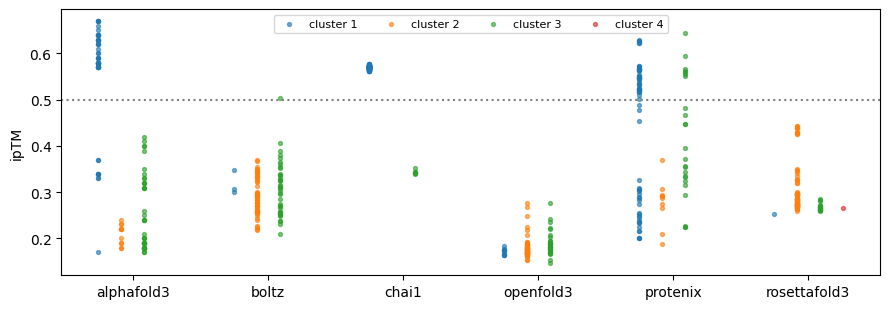

In [2]:
display(pd.crosstab(models.backend, models.cluster, margins=True))
fig, ax = plt.subplots(figsize=(9, 3.2))
engines = sorted(models.backend.unique())
for k, c in enumerate(sorted(models.cluster.unique())):
    d = models[models.cluster == c]
    ax.scatter([engines.index(b) + (k - 1.5) * 0.17 for b in d.backend], d.iptm, s=8, alpha=0.6, label=f"cluster {c}")
ax.set_xticks(range(len(engines)), engines); ax.set_ylabel("ipTM"); ax.axhline(CONF_IPTM, ls=":", c="grey")
ax.legend(fontsize=8, ncol=4); fig.tight_layout(); fig.savefig(OUT / "iptm_by_engine_cluster.png", dpi=150)
models.groupby("cluster").iptm.describe().round(2)

**Cluster 1 is the confident pose**: median ipTM 0.57, carried by Chai-1, AlphaFold3 and Protenix. Clusters 2 and 3
sit around ipTM 0.27, and cluster 4 is a single model. Results are given for cluster 1, for the ipTM ≥ 0.5 subset
and for all models.

## 2. Which tryptophans sit in AGO1 cavities?

In [3]:
def trp_summary(df):
    w = df.iptm; b = df.indole_in_cavity >= 0.5
    return pd.Series({"n_models": len(df), "buried": b.mean(), "buried_iptm_w": (b * w).sum() / w.sum(),
                      "in_channel": df.in_channel.mean(), "depth_max_med": df.sub_depth_max.median(),
                      "sub_volume_med": df.sub_volume.median(), "n_contacts_med": df.n_contacts.median(),
                      "trp_plddt_med": df.trp_plddt.median()})

groups = {"all": trp, f"ipTM≥{CONF_IPTM}": trp[trp.iptm >= CONF_IPTM],
          **{f"cluster {c}": trp[trp.cluster == c] for c in (1, 2, 3)}}
summ = pd.concat({g: d.groupby("trp").apply(trp_summary, include_groups=False) for g, d in groups.items()}, names=["group"])
summ.round(2)

n_models  buried  buried_iptm_w  in_channel  depth_max_med  sub_volume_med  n_contacts_med  trp_plddt_med
group     trp                                                                                                           
all       225     600.0    0.02           0.02        0.06           0.00            0.00             3.0          62.47
          258     600.0    0.67           0.64        0.76           3.50          424.98             4.0          33.41
          275     600.0    0.87           0.85        0.90           4.84          762.70             5.0          33.27
          295     600.0    0.81           0.85        0.82           4.61          618.19             5.0          27.96
          313     600.0    0.65           0.69        0.58           3.74          186.30             6.0          33.68
ipTM≥0.5  225     181.0    0.00           0.00        0.01           0.00            0.00             4.0          72.00
          258     181.0    0.52           0.52        0.70           2.55          241.27             4.0          33.69
          275     181.0    0.78           0.78        0.86           4.24          568.51             5.0          33.81
          295     181.0    0.96           0.96        0.96           4.84          794.66             5.0          28.21
          313     181.0    0.78           0.77        0.75           4.53          331.56             6.0          34.12
cluster 1 225     222.0    0.00           0.00        0.01           0.00            0.00             4.0          68.30
          258     222.0    0.53           0.52        0.69           2.55          245.70             4.0          33.70
          275     222.0    0.79           0.79        0.86           4.55          604.91             5.5          33.82
          295     222.0    0.95           0.96        0.95           4.84          795.64             5.0          28.21
          313     222.0    0.73           0.75        0.71           4.53          283.39             6.0          34.13
cluster 2 225     223.0    0.03           0.03        0.05           0.00            0.00             3.0          60.18
          258     223.0    0.80           0.82        0.83           4.84          626.18             6.0          28.47
          275     223.0    0.92           0.93        0.92           4.98          819.50             5.0          27.22
          295     223.0    0.75           0.75        0.76           4.41          504.79             6.0          28.17
          313     223.0    0.68           0.70        0.52           4.02          146.45             6.0          31.08
cluster 3 225     154.0    0.05           0.05        0.14           0.00            0.00             3.0          58.22
          258     154.0    0.69           0.72        0.74           4.14          542.81             4.0          28.73
          275     154.0    0.92           0.92        0.93           4.80          889.38             4.0          27.34
          295     154.0    0.68           0.68        0.73           3.50          358.34             5.0          26.89
          313     154.0    0.49           0.51        0.47           1.70           75.17             4.0          30.82

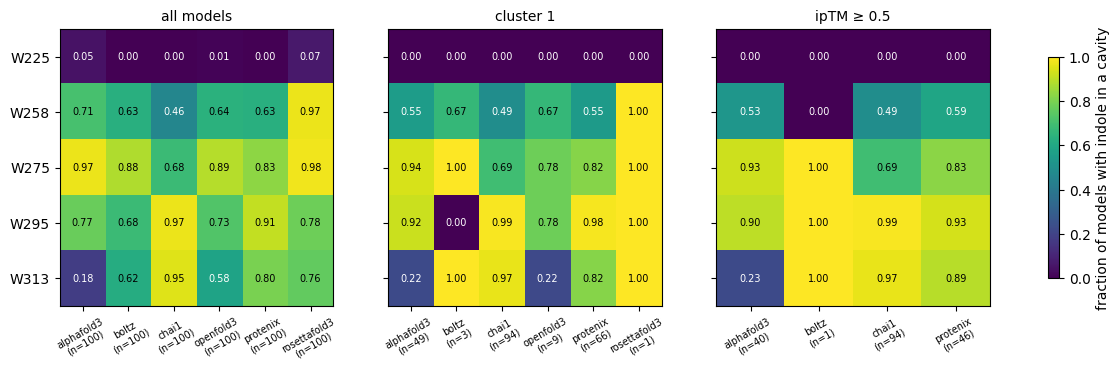

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (title, d) in zip(axes, [("all models", trp), ("cluster 1", trp[trp.cluster == 1]), (f"ipTM ≥ {CONF_IPTM}", trp[trp.iptm >= CONF_IPTM])]):
    piv = d.assign(b=d.indole_in_cavity >= 0.5).pivot_table(index="trp", columns="backend", values="b", aggfunc="mean")
    n = d.drop_duplicates("model_id").backend.value_counts()
    im = ax.imshow(piv.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(piv.shape[1]), [f"{b}\n(n={n.get(b, 0)})" for b in piv.columns], fontsize=7, rotation=30)
    ax.set_yticks(range(len(piv)), [f"W{w}" for w in piv.index]); ax.set_title(title, fontsize=10)
    for (i, j), v in np.ndenumerate(piv.values):
        if not np.isnan(v): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v < 0.6 else "k")
fig.colorbar(im, ax=axes, shrink=0.8, label="fraction of models with indole in a cavity")
fig.savefig(OUT / "trp_buried_by_engine.png", dpi=150, bbox_inches="tight")

**Reading.**
* **W258, W275, W295 and W313**, all in FBW2's acidic C-terminal tail, have their indole inside an AGO1 cavity in
  most models (65–87 % over all 600 models), mostly within the central nucleic-acid channel. Burial is broadly
  shared by the engines, but not uniform: e.g. W313 is buried in 22 % of AlphaFold3 and OpenFold3 cluster-1 models
  against 97–100 % for Chai-1 and Boltz, and W258 is buried in 53 % of cluster-1 vs 80 % of cluster-2 models.
* **W275** is the most often buried over all models (87 %). In the confident cluster 1, **W295** is the most buried
  (95 %, 4.8 Å deep sub-pocket), followed by W275 (79 %) and W313 (73 %).
* **W225** (LRR domain, folded, pLDDT ≈ 65) is essentially **never** in a cavity (≤ 3 % of models): it touches the
  AGO1 surface (see §4).
* The tail Trps have low pLDDT (≈ 30) in every engine, so the tail's exact register is uncertain even when its
  burial is not. That is why the next sections look at **AGO1 pockets** rather than individual Trp.

## 3. Contacts per Trp and AGO1 residue

In [5]:
plip = pd.read_csv(tp.ABCFOLD / "all_selected_summary.csv")
plip["model_id"] = plip.replica.astype(str) + "/" + plip.model
plip_trp = (plip[(plip.reschain_lig == tp.PREY) & plip.resnr_lig.isin(TRP)]
            .groupby(["model_id", "resnr_lig", "resnr"]).interaction_type.agg(lambda x: ",".join(sorted(set(x))))
            .rename("plip").reset_index().rename(columns={"resnr_lig": "trp", "resnr": "ago1_resnr"}))
res = res.merge(plip_trp, on=["model_id", "trp", "ago1_resnr"], how="outer").merge(meta, on="model_id")
for c in ("lines_subpocket", "indole_contact"): res[c] = res[c].astype("boolean").fillna(False).astype(bool)
res["uniprot_resnr"] = res.ago1_resnr.map(tp.model_to_uniprot)
res["hit"] = res.indole_contact | res.plip.notna()          # direct contact with that Trp
names = {}
for ch in gemmi.read_structure(models.pdb.iloc[0])[0]:
    if ch.name == tp.BAIT: names = {tp.model_to_uniprot(r.seqid.num): gemmi.find_tabulated_residue(r.name).one_letter_code.upper() for r in ch}
lab = lambda u: f"{names.get(u, '?')}{u}"

cdd = pd.read_parquet(ANNOT / "cdd_sites.parquet")
cdd = cdd[(cdd.pair == "O04379__Q9ZPE4") & (cdd.chain == "A") & cdd.site.notna()]
site_of = {}
for _, r in cdd.iterrows():
    for p in r.residues: site_of.setdefault(int(p), []).append(f"{r.cdd_name.split('_')[0]}: {r.site}")
doms = [d for d in yaml.safe_load(open(ANNOT / "O04379__Q9ZPE4/annotation.yaml"))["domains"]["A"] if d["kind"] == "domain"]
domain_of = lambda n: next((d["name"].replace("Protein argonaute, ", "").replace("Argonaute ", "") for d in doms
                            if d["start"] <= n <= d["end"]), "-")

def contact_frac(ids, by_trp=True):
    # fraction of models in `ids` where the AGO1 residue contacts (that / any) Trp
    r = res[res.model_id.isin(ids) & res.hit]
    keys = (["trp"] if by_trp else []) + ["uniprot_resnr"]
    return (r.groupby(keys).model_id.nunique() / len(ids)).rename("frac")

c1 = meta[meta.cluster == 1].model_id
tab = contact_frac(c1).reset_index().sort_values(["trp", "frac"], ascending=[True, False])
print("Cluster 1: top AGO1 contacts of each Trp (fraction of the 222 models)")
for w in TRP:
    t = tab[tab.trp == w].head(10)
    print(f"  W{w}: " + "  ".join(f"{lab(u)} {f:.2f}" for u, f in zip(t.uniprot_resnr, t.frac)))

Cluster 1: top AGO1 contacts of each Trp (fraction of the 222 models)
  W225: G429 0.82  R428 0.75  H427 0.68  N430 0.33  M431 0.31  T426 0.21  A278 0.14  R432 0.07  G279 0.03  Y469 0.02
  W258: R283 0.46  R285 0.42  D273 0.40  E284 0.21  R433 0.19  R488 0.16  N490 0.15  E275 0.14  L271 0.10  F450 0.10
  W275: R436 0.23  S506 0.18  K507 0.18  R222 0.17  R504 0.17  G420 0.16  T381 0.16  Y505 0.14  L509 0.14  L517 0.14
  W295: Q936 0.22  I935 0.22  L518 0.20  R974 0.18  H986 0.18  K886 0.17  Y983 0.17  I978 0.14  C522 0.13  N722 0.13
  W313: N722 0.31  C972 0.27  L725 0.24  K726 0.23  R971 0.23  Q718 0.18  M591 0.18  T973 0.17  M629 0.16  A970 0.16



### PLIP contact maps per engine: AGO1 PAZ → C-terminus × FBW2 220 → C-terminus
Same map as in the ColabFold notebook, for the ABCfold ensemble. One panel per engine (100 models each) and one
pooled panel (600 models). **Colour = fraction of the models in the panel that have a PLIP contact between the two
residues.** x: AGO1 from the PAZ domain (391) to the end, in UniProt numbering (model residues 332+ shifted by 2).
y: FBW2 from residue 220 (last LRR repeat; the LRR ends at 244) to the C-terminus. Red labels are the Trp. The top strip shows AGO1 domains and
CDD sites (▲ nucleic-acid interface, ● active site, ■ 5′ guide anchoring).


,FBW2,AGO1,frac_all,n_engines
58,R222,E467,0.30,4
2564,D264,K422,0.26,6
844,V248,Y469,0.24,4
1428,D253,R428,0.24,6
1073,F251,Y464,0.21,6
1243,Y252,Y464,0.19,6
2567,D264,K434,0.19,4
57,R222,H466,0.18,4
4119,E279,R940,0.17,6
2254,D260,N485,0.17,5


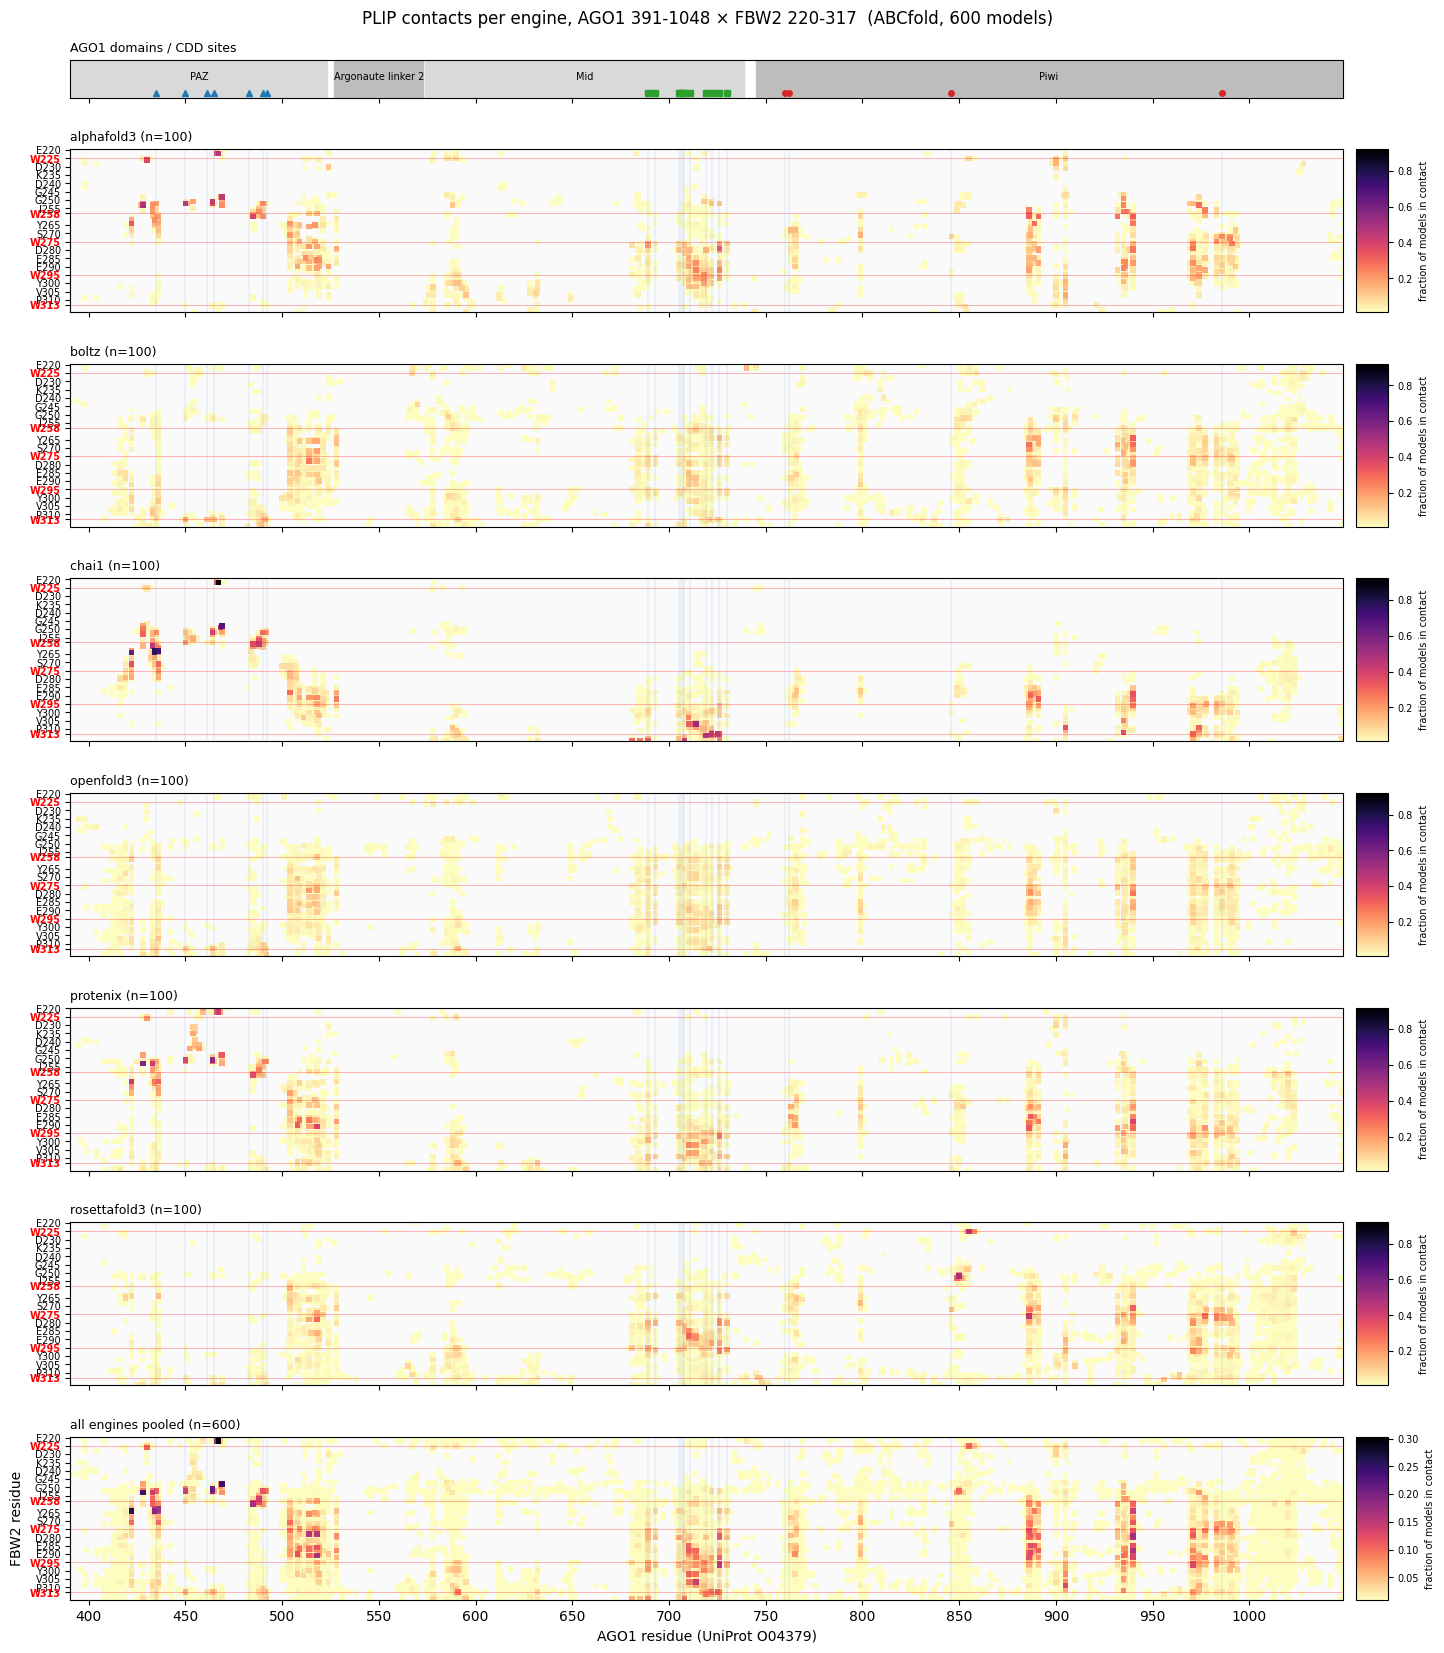

In [6]:

from matplotlib.gridspec import GridSpec
paz_start = next(d["start"] for d in doms if "PAZ" in d["name"])
FBW2_START = 220      # last LRR repeat (LRR ends at 244) + the C-terminal tail
xs = np.arange(paz_start, 1049); ys = np.arange(FBW2_START, 318)
fbw2_seq = {r.seqid.num: gemmi.find_tabulated_residue(r.name).one_letter_code.upper()
            for r in gemmi.read_structure(models.pdb.iloc[0])[0][tp.PREY]}

pc = plip[(plip.reschain == tp.BAIT) & (plip.reschain_lig == tp.PREY)].merge(meta[["model_id", "backend"]], on="model_id")
pc["u"] = pc.resnr.map(tp.model_to_uniprot)
pc = pc[pc.u.between(xs[0], xs[-1]) & pc.resnr_lig.between(ys[0], ys[-1])].drop_duplicates(["model_id", "u", "resnr_lig"])
n_models = meta.backend.value_counts()

def frac_grid(df, n):
    g = np.zeros((len(ys), len(xs)))
    for (y, x), k in df.groupby(["resnr_lig", "u"]).size().items(): g[y - ys[0], x - xs[0]] = k / n
    return g
engines = sorted(meta.backend.unique())
panels = [(f"{b} (n={n_models[b]})", frac_grid(pc[pc.backend == b], n_models[b])) for b in engines]
panels.append((f"all engines pooled (n={len(meta)})", frac_grid(pc, len(meta))))
vmax = max(g.max() for _, g in panels[:-1])

fig = plt.figure(figsize=(17, 20))
gs = GridSpec(len(panels) + 1, 2, width_ratios=[40, 1], height_ratios=[0.7] + [3] * len(panels), hspace=0.35, wspace=0.02)
ax_top = fig.add_subplot(gs[0, 0])
for k, d in enumerate([d for d in doms if d["end"] >= xs[0]]):
    ax_top.axvspan(max(d["start"], xs[0]), d["end"], color=["#d9d9d9", "#bdbdbd"][k % 2])
    ax_top.text((max(d["start"], xs[0]) + d["end"]) / 2, 0.55, d["name"].replace("Protein argonaute, ", "").replace(" domain", ""), ha="center", va="center", fontsize=7)
mk = {"nucleic acid": ("^", "tab:blue"), "active site": ("o", "tab:red"), "anchoring": ("s", "tab:green")}
for u, ss in site_of.items():
    for s_ in ss:
        for key, (m_, c_) in mk.items():
            if key in s_ and u >= xs[0]: ax_top.plot(u, 0.12, m_, color=c_, ms=4)
ax_top.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax_top.set_ylim(0, 1); ax_top.set_yticks([]); ax_top.tick_params(labelbottom=False)
ax_top.set_title("AGO1 domains / CDD sites", fontsize=9, loc="left")

trp_in = [w for w in TRP if ys[0] <= w <= ys[-1]]
ticks = sorted({y for y in ys[::5] if all(abs(y - w) > 2 for w in trp_in)} | set(trp_in))
for r, (title, g) in enumerate(panels, start=1):
    ax = fig.add_subplot(gs[r, 0], sharex=ax_top); cax = fig.add_subplot(gs[r, 1])
    yy, xx = np.nonzero(g); order = np.argsort(g[yy, xx])
    last = r == len(panels)
    im_ = ax.scatter(xs[xx[order]], ys[yy[order]], c=g[yy, xx][order], cmap="magma_r", vmin=0.01,
                     vmax=(g.max() if last else vmax), marker="s", s=16, linewidths=0)
    ax.set_facecolor("#fafafa"); ax.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax.set_ylim(ys[-1] + 0.5, ys[0] - 0.5)
    ax.set_yticks(ticks); ax.set_yticklabels([f"{fbw2_seq[y]}{y}" for y in ticks], fontsize=7)
    for lbl, y in zip(ax.get_yticklabels(), ticks):
        if y in TRP: lbl.set_color("red"); lbl.set_fontweight("bold")
    for w in trp_in: ax.axhline(w, color="red", lw=0.5, alpha=0.4)
    for u in set(site_of):
        if u >= xs[0]: ax.axvline(u, color="tab:blue", lw=0.25, alpha=0.4)
    ax.set_title(title, fontsize=9, loc="left"); cb = fig.colorbar(im_, cax=cax)
    cb.set_label("fraction of models in contact", fontsize=7); cax.tick_params(labelsize=7)
    ax.tick_params(labelbottom=last)
ax.set_xticks(np.arange(400, 1049, 50)); ax.set_xlabel("AGO1 residue (UniProt O04379)"); ax.set_ylabel("FBW2 residue")
fig.suptitle(f"PLIP contacts per engine, AGO1 {xs[0]}-{xs[-1]} × FBW2 {ys[0]}-{ys[-1]}  (ABCfold, 600 models)", y=0.905)
fig.savefig(OUT / "plip_contact_maps_per_engine.png", dpi=150, bbox_inches="tight")

top = (pc.groupby(["resnr_lig", "u"]).agg(frac_all=("model_id", lambda x: x.nunique() / len(meta)),
                                         n_engines=("backend", "nunique")).reset_index()
         .sort_values("frac_all", ascending=False).head(15))
top["FBW2"] = [f"{fbw2_seq[y]}{y}" for y in top.resnr_lig]; top["AGO1"] = [f"{names.get(u, '?')}{u}" for u in top.u]
top[["FBW2", "AGO1", "frac_all", "n_engines"]].round(2)


## 4. Pocket view: which Trp fills which AGO1 pocket?

The contacts above group into **five recurrent AGO1 sites**. They are defined from the contact lists and the CDD
annotation, in UniProt numbering:

| site | residues | annotation |
|---|---|---|
| **slicer pocket** | D760, D846, H986 (catalytic) + K886, R887, R940, S977, I978, Y983, I935, Q936, R974 | CDD *Piwi active site*, the W275 pocket of the ColabFold notebook |
| **MID 5′ pocket** | CDD *5′ guide anchoring site* + Q718, N722, L725, K726, A970–T973 | CDD *Piwi: 5′ RNA guide strand anchoring site* |
| **PAZ/L1 groove** | T381, G420, R436, R504–L509, L517, L518 | PAZ domain / linker 1 |
| **N-domain groove** | R222, L271, D273, R283–R285, R326 | N domain |
| **PAZ surface** | T426–N430 (H427, R428, G429) | PAZ, outside the CDD nucleic-acid interface |

A Trp is assigned to a site in a model when it contacts ≥ 2 of the site's residues (the best-matching site wins).

Fraction of models with ANY Trp in the site


,cluster 1,cluster 2,cluster 3,alphafold3,boltz,chai1,openfold3,protenix,rosettafold3
slicer pocket,0.51,0.46,0.52,0.59,0.34,0.50,0.38,0.50,0.65
MID 5′ pocket,0.52,0.41,0.36,0.36,0.37,0.77,0.48,0.29,0.36
PAZ/L1 groove,0.46,0.35,0.17,0.33,0.27,0.50,0.30,0.30,0.36
N-domain groove,0.50,0.30,0.16,0.46,0.31,0.29,0.11,0.49,0.35
PAZ surface,0.82,0.00,0.00,0.47,0.02,0.94,0.01,0.40,0.00


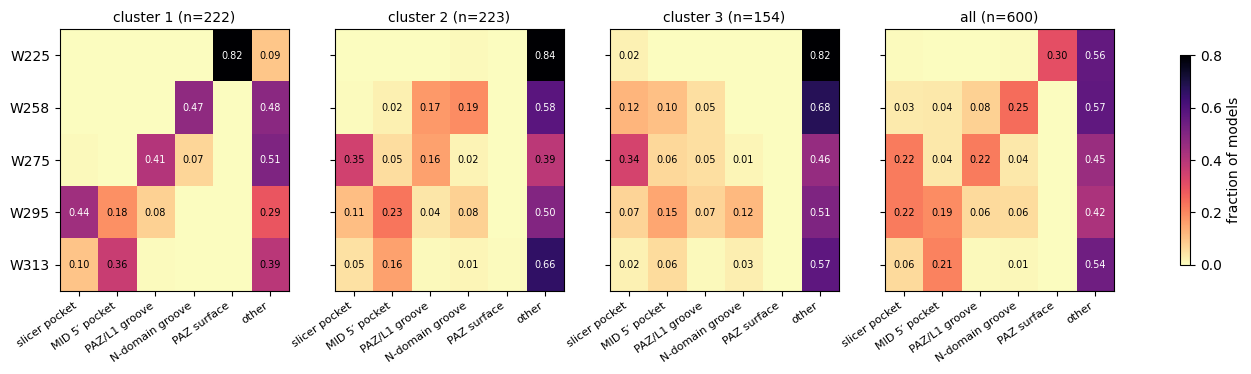

In [7]:
anch = {int(p) for p in cdd[cdd.site.str.contains("anchoring")].residues.iloc[0]}
SITES = {
    "slicer pocket":   {760, 846, 986, 886, 887, 940, 977, 978, 983, 935, 936, 974},
    "MID 5′ pocket":   anch | {718, 722, 725, 726, 970, 971, 972, 973},
    "PAZ/L1 groove":   {381, 420, 436, 504, 505, 506, 507, 509, 517, 518},
    "N-domain groove": {222, 271, 273, 283, 284, 285, 326},
    "PAZ surface":     {426, 427, 428, 429, 430},
}
rows = []
for (mid, w), g in res[res.hit].groupby(["model_id", "trp"]):
    us = set(g.uniprot_resnr)
    best = max(SITES, key=lambda k: len(us & SITES[k]))
    rows.append((mid, w, best if len(us & SITES[best]) >= 2 else "other"))
occ = pd.DataFrame(rows, columns=["model_id", "trp", "site"]).merge(meta, on="model_id")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
site_cols = list(SITES) + ["other"]
for ax, c in zip(axes, [1, 2, 3, "all"]):
    ids = meta.model_id if c == "all" else meta[meta.cluster == c].model_id
    o = occ[occ.model_id.isin(ids)]
    piv = (pd.crosstab(o.trp, o.site) / len(ids)).reindex(index=TRP, columns=site_cols, fill_value=0)
    im = ax.imshow(piv.values, vmin=0, vmax=0.8, cmap="magma_r", aspect="auto")
    ax.set_xticks(range(len(site_cols)), site_cols, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(TRP)), [f"W{w}" for w in TRP])
    ax.set_title(f"cluster {c} (n={len(ids)})" if c != "all" else f"all (n={len(ids)})", fontsize=10)
    for (i, j), v in np.ndenumerate(piv.values):
        if v >= 0.01: ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v > 0.4 else "k")
fig.colorbar(im, ax=axes, shrink=0.8, label="fraction of models")
fig.savefig(OUT / "trp_site_occupancy.png", dpi=150, bbox_inches="tight")

# any Trp in each site, per cluster and per engine
site_any = pd.DataFrame({
    **{f"cluster {c}": {s: occ[(occ.cluster == c) & (occ.site == s)].model_id.nunique() / (meta.cluster == c).sum() for s in SITES} for c in (1, 2, 3)},
    **{b: {s: occ[(occ.backend == b) & (occ.site == s)].model_id.nunique() / (meta.backend == b).sum() for s in SITES} for b in engines},
})
print("Fraction of models with ANY Trp in the site"); site_any.round(2)

In [8]:
# Which Trp occupies the slicer pocket, per engine (all clusters)
o = occ[occ.site == "slicer pocket"]
(pd.crosstab(o.backend, o.trp).div(meta.backend.value_counts(), axis=0)).reindex(columns=TRP, fill_value=0).round(2)

trp,225,258,275,295,313
backend,,,,,
alphafold3,0.01,0.00,0.27,0.32,0.00
boltz,0.01,0.08,0.19,0.08,0.00
chai1,0.00,0.00,0.00,0.42,0.12
openfold3,0.00,0.06,0.26,0.06,0.03
protenix,0.00,0.02,0.08,0.34,0.12
rosettafold3,0.01,0.04,0.52,0.11,0.09


**Reading.**
* **The slicer pocket is filled by a tail Trp in ≈ 50 % of models in every cluster**, and by every engine. Which
  Trp fills it changes with the pose: **W295** in cluster 1 (44 %), **W275** in clusters 2 and 3 (≈ 35 %), as in
  the ColabFold models.
* The **MID 5′ pocket** (CDD guide-anchoring site) is the second robust site (36–52 % of models): **W313** in
  cluster 1, W295 in cluster 2.
* In cluster 1 the tail fills the channel in a fixed order: **W258 → N-domain groove, W275 → PAZ/L1, W295 → slicer
  pocket, W313 → MID 5′ pocket**. In clusters 2 and 3 the tail shifts by one Trp (W275 in the slicer pocket).
* **W225** (folded LRR) packs on the **PAZ surface** (H427/R428/G429) in ≈ 80 % of cluster-1 models. This is a
  surface contact (never a cavity), so it is *not* a pocket candidate. It is also engine-dependent: Chai-1 94 %,
  AlphaFold3 47 %, Protenix 40 %, other engines ≈ 0, and cluster 1 is Chai-1-heavy.

So the AGO1 **pockets** are robust while the Trp→pocket **register** is not. Mutating an AGO1 pocket, or several
Trps together, is a safer test than a single W→A.


## 4b. Does miR168 deplete the AGO1–FBW2 contacts?
The same 600-model ABCfold protocol (6 engines × 100 models) was run with the **miR168** guide RNA added
(`results/ago1_fbw2_mir168`; AGO1 + FBW2 + 21-nt RNA, chain C). If FBW2's acidic tail needs the *empty* RNA channel,
its PLIP contacts with AGO1 should drop when the RNA is present. Both sets have exactly 100 models per engine, so
panels are compared engine by engine and pooled with equal engine weights. Same boundaries as above: AGO1 391–1048
(UniProt numbering), FBW2 220–317. In this run's PLIP table FBW2 is numbered 1051–1367 (concatenated chains), which is
shifted back here.

**Caveat:** the two sets were clustered and ranked independently, so only the *engine-matched* comparisons are fair;
ipTM and the pose-cluster mix differ between the sets.


In [9]:

MIRDIR = tp.ABCFOLD.parent / "ago1_fbw2_mir168"
sel_m = pd.read_csv(MIRDIR / "selected_models.csv")
sel_m["model_id"] = sel_m.cluster.astype(str) + "/" + sel_m.staged_cif.map(lambda p: Path(p).stem)
meta_m = sel_m[["model_id", "cluster", "backend", "iptm"]]
assert meta_m.backend.value_counts().eq(100).all() and meta.backend.value_counts().eq(100).all()

def contact_pairs(path, meta_, fbw2_offset=0):
    # AGO1 (chain A) x FBW2 (chain B) PLIP residue pairs, one row per (model, AGO1 residue, FBW2 residue)
    d = pd.read_csv(path)
    d = d[(d.reschain == "A") & (d.reschain_lig == "B")].copy()
    d["model_id"] = d.replica.astype(str) + "/" + d.model
    d["y"] = d.resnr_lig - fbw2_offset; d["u"] = d.resnr.map(tp.model_to_uniprot)
    d = d[d.u > 0].drop_duplicates(["model_id", "u", "y"])
    assert set(d.model_id) <= set(meta_.model_id)
    return d.merge(meta_[["model_id", "backend"]], on="model_id")[["model_id", "backend", "u", "y"]]

P_apo = contact_pairs(tp.ABCFOLD / "all_selected_summary.csv", meta)
P_mir = contact_pairs(MIRDIR / "all_selected_summary.csv", meta_m, fbw2_offset=1050)
in_region = lambda d: d[d.u.between(xs[0], xs[-1]) & d.y.between(ys[0], ys[-1])]
R_apo, R_mir = in_region(P_apo), in_region(P_mir)

# miR168 <-> AGO1 PLIP contacts (fraction of the 600 models in which the RNA touches each AGO1 residue)
mr = pd.read_csv(MIRDIR / "all_selected_summary_mir_ligands.csv")
mr = mr[(mr.reschain == "A") & (mr.reschain_lig == "C")].copy()
mr["model_id"] = mr.replica.astype(str) + "/" + mr.model; mr["u"] = mr.resnr.map(tp.model_to_uniprot)
mir_track = mr[mr.u > 0].drop_duplicates(["model_id", "u"]).groupby("u").size().reindex(range(1, 1049), fill_value=0) / len(meta_m)
print(f"models with FBW2-AGO1 contacts: apo {P_apo.model_id.nunique()}/600, +miR168 {P_mir.model_id.nunique()}/600;"
      f" models with miR168-AGO1 contacts: {mr.model_id.nunique()}/600")


models with FBW2-AGO1 contacts: apo 600/600, +miR168 600/600; models with miR168-AGO1 contacts: 600/600


In [10]:

# ---- number of AGO1-FBW2 residue pairs in contact per model (zero-contact models count as 0) ----
rng = np.random.default_rng(0)
def per_model(P, meta_):
    return P.groupby("model_id").size().reindex(meta_.model_id, fill_value=0).values

def ratio_ci(a, b, n=4000):
    # ratio of means (b / a) with a 95 % bootstrap CI
    ia, ib = rng.integers(0, len(a), (n, len(a))), rng.integers(0, len(b), (n, len(b)))
    r = b[ib].mean(1) / np.maximum(a[ia].mean(1), 1e-9)
    return np.percentile(r, [2.5, 97.5])

rows = []
for scope, (Pa, Pm) in {"all AGO1 × all FBW2": (P_apo, P_mir), f"region (AGO1 {xs[0]}-{xs[-1]} × FBW2 {ys[0]}-{ys[-1]})": (R_apo, R_mir)}.items():
    for b in engines + ["all engines"]:
        ma = meta if b == "all engines" else meta[meta.backend == b]
        mm = meta_m if b == "all engines" else meta_m[meta_m.backend == b]
        a, m_ = per_model(Pa, ma), per_model(Pm, mm)
        lo, hi = ratio_ci(a, m_)
        rows.append(dict(scope=scope, engine=b, apo_pairs=a.mean(), mir168_pairs=m_.mean(), ratio=m_.mean() / a.mean(), ci_lo=lo, ci_hi=hi))
summ_mir = pd.DataFrame(rows)
summ_mir.round(2)


,scope,engine,apo_pairs,mir168_pairs,ratio,ci_lo,ci_hi
0,all AGO1 × all FBW2,alphafold3,101.30,39.82,0.39,0.36,0.43
1,all AGO1 × all FBW2,boltz,174.36,133.16,0.76,0.71,0.82
2,all AGO1 × all FBW2,chai1,129.39,96.02,0.74,0.70,0.78
3,all AGO1 × all FBW2,openfold3,132.64,65.70,0.50,0.45,0.54
4,all AGO1 × all FBW2,protenix,131.65,47.28,0.36,0.32,0.40
5,all AGO1 × all FBW2,rosettafold3,203.33,92.18,0.45,0.36,0.55
6,all AGO1 × all FBW2,all engines,145.44,79.03,0.54,0.50,0.58
7,region (AGO1 391-1048 × FBW2 220-317),alphafold3,75.16,23.69,0.32,0.28,0.35
8,region (AGO1 391-1048 × FBW2 220-317),boltz,76.73,36.17,0.47,0.43,0.52
9,region (AGO1 391-1048 × FBW2 220-317),chai1,69.23,58.52,0.85,0.80,0.89


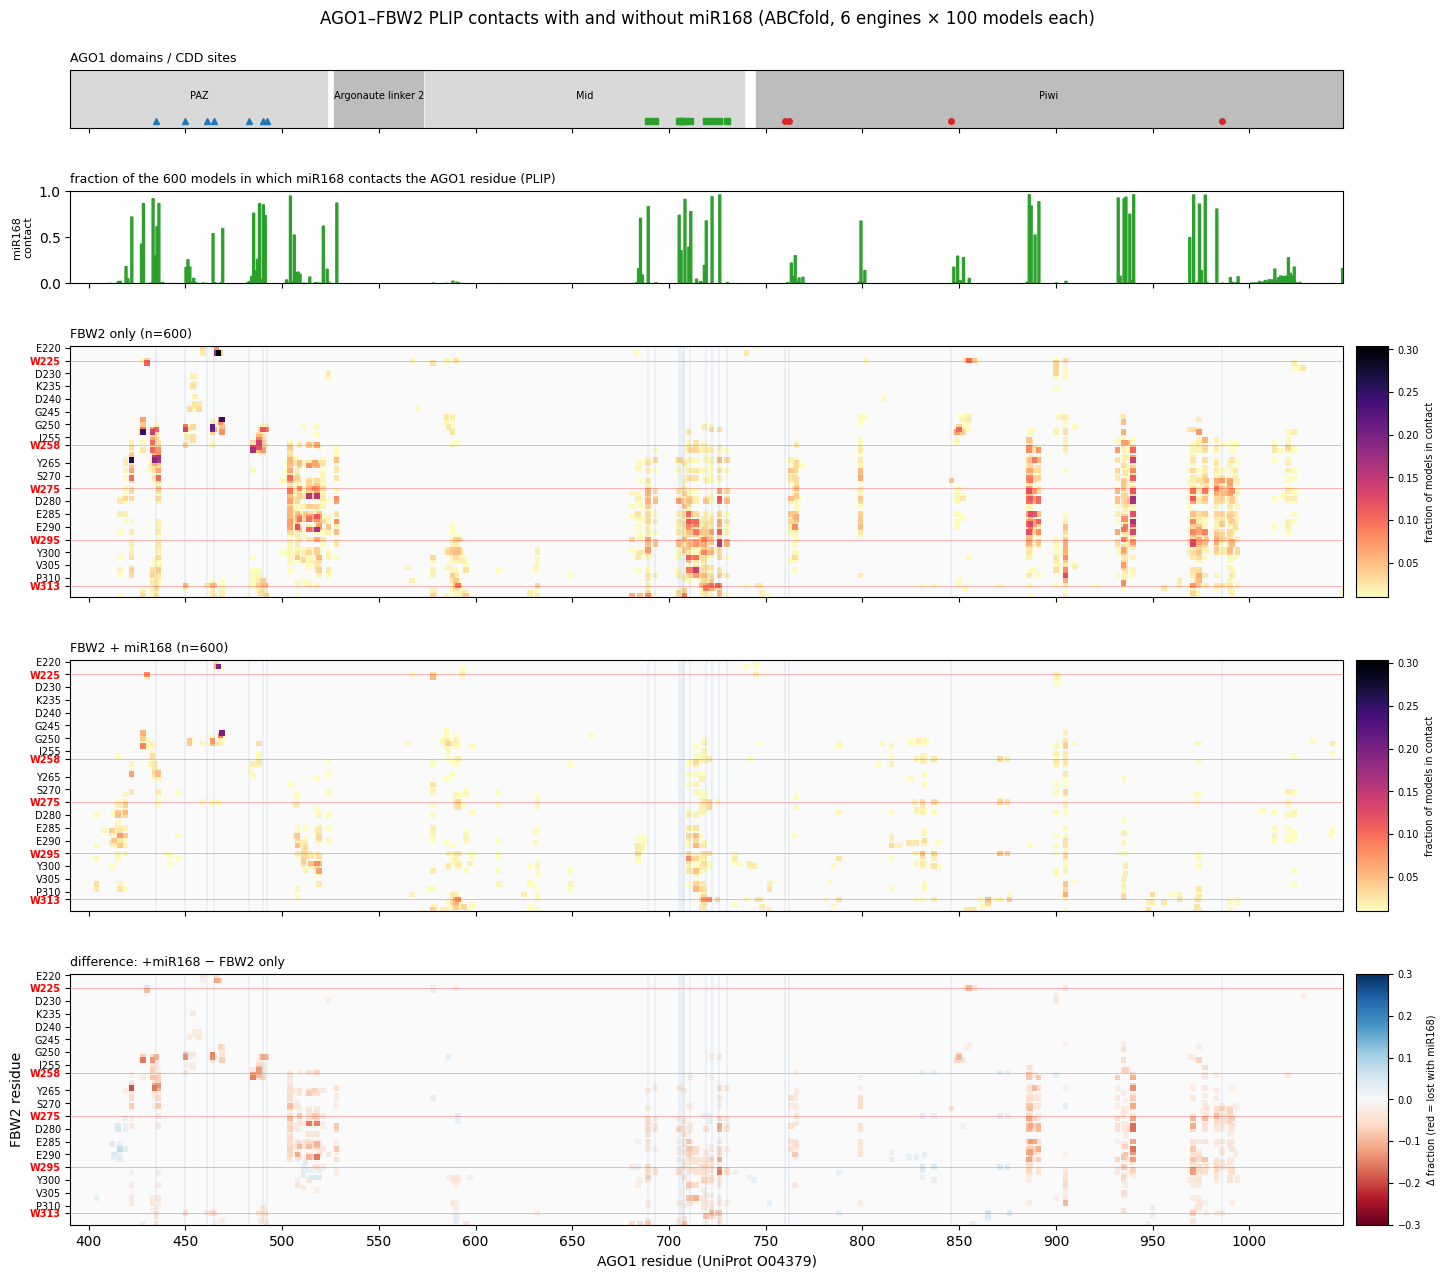

In [11]:

# ---- maps: miR168 track, apo, +miR168, difference (pooled) ----
def frac_grid2(df, n):
    g = np.zeros((len(ys), len(xs)))
    for (y, x), k in df.groupby(["y", "u"]).size().items(): g[y - ys[0], x - xs[0]] = k / n
    return g
G_apo, G_mir = frac_grid2(R_apo, len(meta)), frac_grid2(R_mir, len(meta_m))
G_diff = G_mir - G_apo
trp_in = [w for w in TRP if ys[0] <= w <= ys[-1]]
ticks = sorted({y for y in ys[::5] if all(abs(y - w) > 2 for w in trp_in)} | set(trp_in))

def style_map(ax, last):
    ax.set_facecolor("#fafafa"); ax.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax.set_ylim(ys[-1] + 0.5, ys[0] - 0.5)
    ax.set_yticks(ticks); ax.set_yticklabels([f"{fbw2_seq[y]}{y}" for y in ticks], fontsize=7)
    for lbl, y in zip(ax.get_yticklabels(), ticks):
        if y in TRP: lbl.set_color("red"); lbl.set_fontweight("bold")
    for w in trp_in: ax.axhline(w, color="red", lw=0.5, alpha=0.4)
    for u in set(site_of):
        if u >= xs[0]: ax.axvline(u, color="tab:blue", lw=0.25, alpha=0.4)
    ax.tick_params(labelbottom=last)

def domain_strip(ax):
    for k, d in enumerate([d for d in doms if d["end"] >= xs[0]]):
        ax.axvspan(max(d["start"], xs[0]), d["end"], color=["#d9d9d9", "#bdbdbd"][k % 2])
        ax.text((max(d["start"], xs[0]) + d["end"]) / 2, 0.55, d["name"].replace("Protein argonaute, ", "").replace(" domain", ""), ha="center", va="center", fontsize=7)
    for u, ss in site_of.items():
        for s_ in ss:
            for key, (m_, c_) in mk.items():
                if key in s_ and u >= xs[0]: ax.plot(u, 0.12, m_, color=c_, ms=4)
    ax.set_xlim(xs[0] - 0.5, xs[-1] + 0.5); ax.set_ylim(0, 1); ax.set_yticks([]); ax.tick_params(labelbottom=False)
    ax.set_title("AGO1 domains / CDD sites", fontsize=9, loc="left")

fig = plt.figure(figsize=(17, 15))
gs = GridSpec(5, 2, width_ratios=[40, 1], height_ratios=[0.7, 1.1, 3, 3, 3], hspace=0.35, wspace=0.02)
ax0 = fig.add_subplot(gs[0, 0]); domain_strip(ax0)
axm = fig.add_subplot(gs[1, 0], sharex=ax0)
axm.fill_between(mir_track.index[mir_track.index >= xs[0]], mir_track[mir_track.index >= xs[0]], step="mid", color="tab:green")
axm.set_ylim(0, 1); axm.set_ylabel("miR168\ncontact", fontsize=8); axm.tick_params(labelbottom=False)
axm.set_title("fraction of the 600 models in which miR168 contacts the AGO1 residue (PLIP)", fontsize=9, loc="left")
vmax = max(G_apo.max(), G_mir.max())
for r, (title, g, cmap, vmin_, vmax_, clab) in enumerate([
        (f"FBW2 only (n={len(meta)})", G_apo, "magma_r", 0.01, vmax, "fraction of models in contact"),
        (f"FBW2 + miR168 (n={len(meta_m)})", G_mir, "magma_r", 0.01, vmax, "fraction of models in contact"),
        ("difference: +miR168 − FBW2 only", G_diff, "RdBu", -0.3, 0.3, "Δ fraction (red = lost with miR168)")], start=2):
    ax = fig.add_subplot(gs[r, 0], sharex=ax0); cax = fig.add_subplot(gs[r, 1])
    keep = np.abs(g) >= (0.02 if r == 4 else 0.01)
    yy, xx = np.nonzero(keep); order = np.argsort(np.abs(g[yy, xx]))
    im_ = ax.scatter(xs[xx[order]], ys[yy[order]], c=g[yy, xx][order], cmap=cmap, vmin=vmin_, vmax=vmax_, marker="s", s=16, linewidths=0)
    style_map(ax, r == 4); ax.set_title(title, fontsize=9, loc="left")
    fig.colorbar(im_, cax=cax).set_label(clab, fontsize=7); cax.tick_params(labelsize=7)
ax.set_xticks(np.arange(400, 1049, 50)); ax.set_xlabel("AGO1 residue (UniProt O04379)"); ax.set_ylabel("FBW2 residue")
fig.suptitle("AGO1–FBW2 PLIP contacts with and without miR168 (ABCfold, 6 engines × 100 models each)", y=0.92)
fig.savefig(OUT / "plip_contact_maps_mir168_vs_apo.png", dpi=150, bbox_inches="tight")


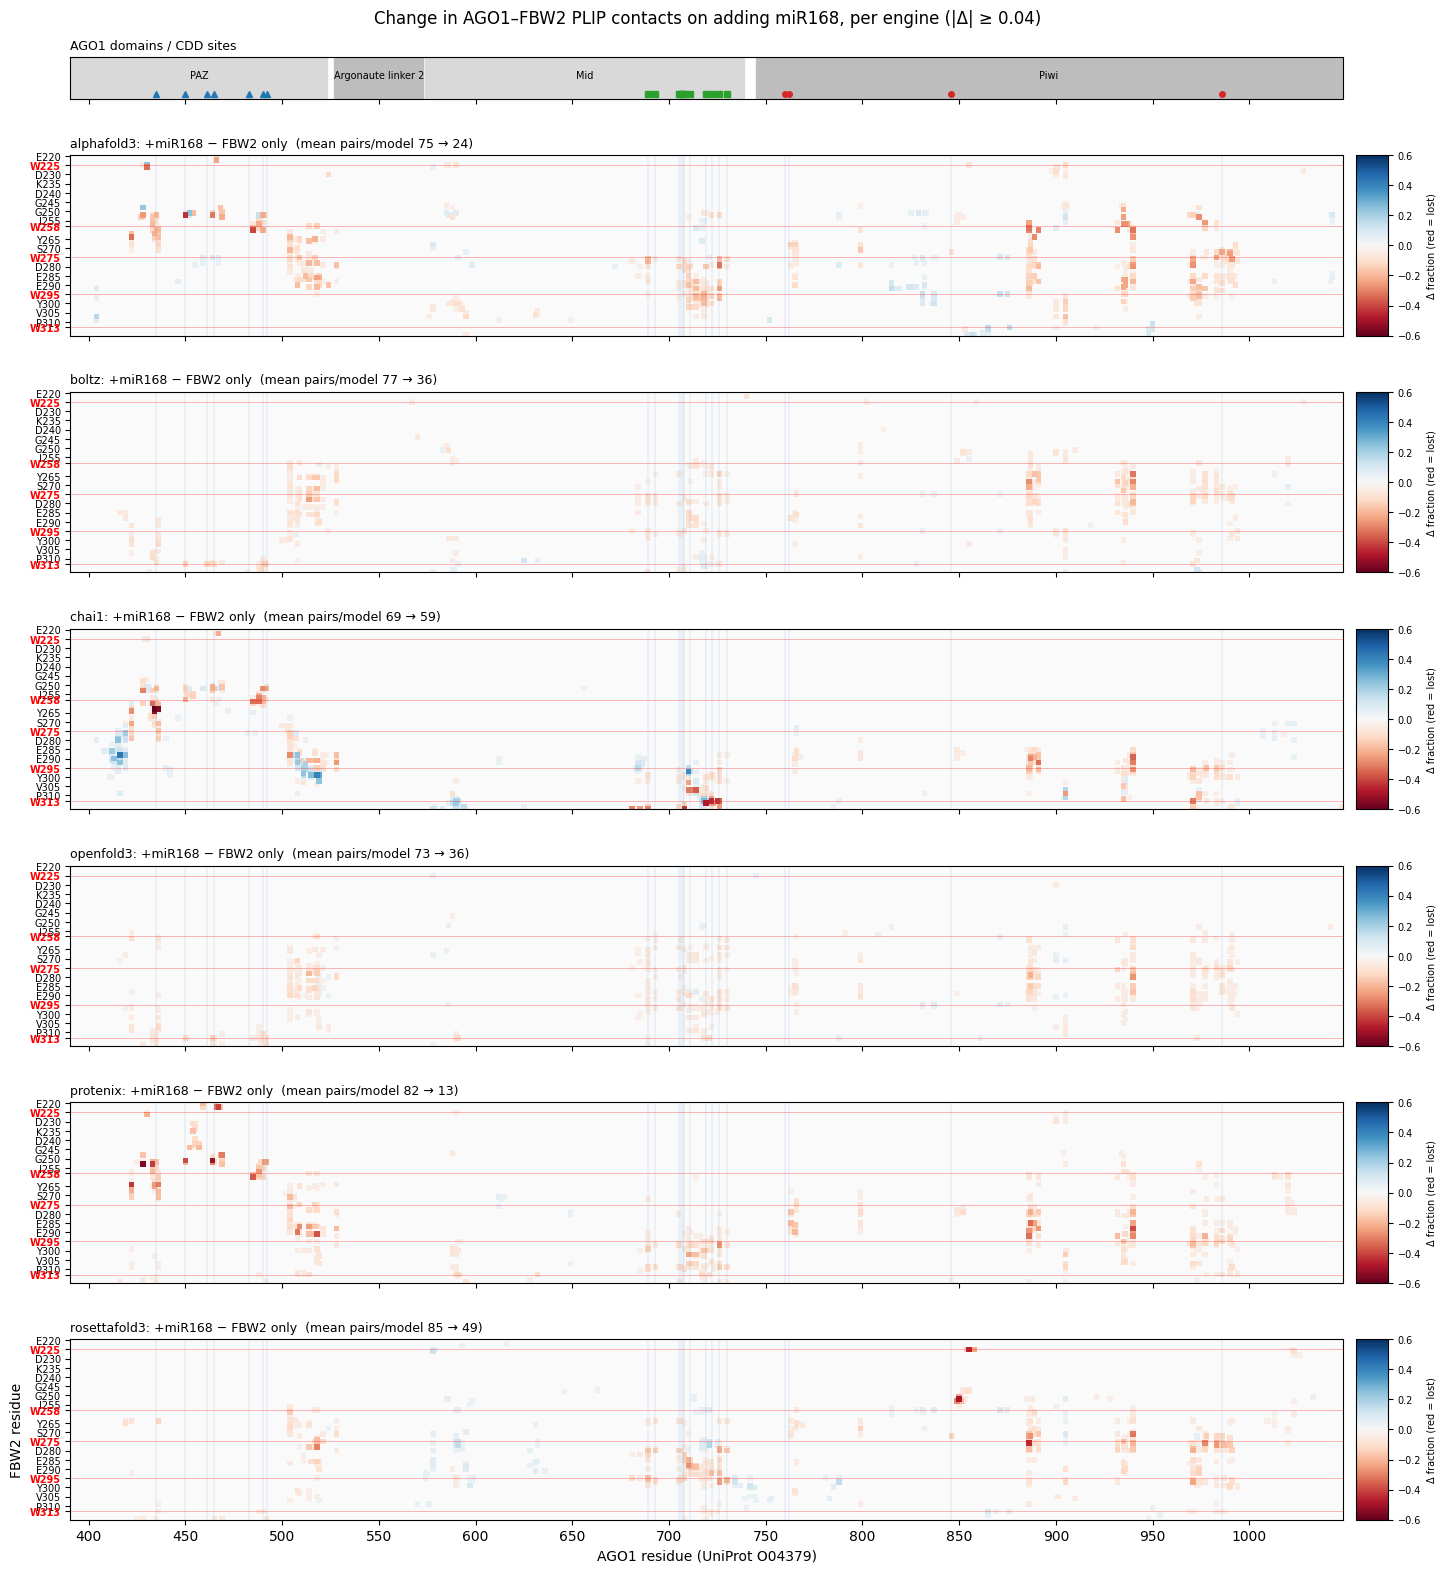

In [12]:

# ---- same difference map, per engine ----
fig = plt.figure(figsize=(17, 19))
gs = GridSpec(7, 2, width_ratios=[40, 1], height_ratios=[0.7] + [3] * 6, hspace=0.35, wspace=0.02)
ax0 = fig.add_subplot(gs[0, 0]); domain_strip(ax0)
for r, b in enumerate(engines, start=1):
    g = (frac_grid2(R_mir[R_mir.backend == b], 100) - frac_grid2(R_apo[R_apo.backend == b], 100))
    ax = fig.add_subplot(gs[r, 0], sharex=ax0); cax = fig.add_subplot(gs[r, 1])
    yy, xx = np.nonzero(np.abs(g) >= 0.04); order = np.argsort(np.abs(g[yy, xx]))
    im_ = ax.scatter(xs[xx[order]], ys[yy[order]], c=g[yy, xx][order], cmap="RdBu", vmin=-0.6, vmax=0.6, marker="s", s=16, linewidths=0)
    style_map(ax, r == 6)
    a, m_ = per_model(R_apo[R_apo.backend == b], meta[meta.backend == b]), per_model(R_mir[R_mir.backend == b], meta_m[meta_m.backend == b])
    ax.set_title(f"{b}: +miR168 − FBW2 only  (mean pairs/model {a.mean():.0f} → {m_.mean():.0f})", fontsize=9, loc="left")
    fig.colorbar(im_, cax=cax).set_label("Δ fraction (red = lost)", fontsize=7); cax.tick_params(labelsize=7)
ax.set_xticks(np.arange(400, 1049, 50)); ax.set_xlabel("AGO1 residue (UniProt O04379)"); ax.set_ylabel("FBW2 residue")
fig.suptitle("Change in AGO1–FBW2 PLIP contacts on adding miR168, per engine (|Δ| ≥ 0.04)", y=0.905)
fig.savefig(OUT / "plip_contact_maps_mir168_vs_apo_per_engine.png", dpi=150, bbox_inches="tight")


In [13]:

# ---- by Trp and by AGO1 pocket: contacts per model, FBW2 only vs +miR168 ----
def per_model_mask(P, meta_, mask):
    return P[mask(P)].groupby("model_id").size().reindex(meta_.model_id, fill_value=0).values

rows = []
for w in TRP:
    a, m_ = (per_model_mask(P, mt, lambda d, w=w: d.y == w) for P, mt in [(P_apo, meta), (P_mir, meta_m)])
    rows.append(dict(group=f"FBW2 W{w}", apo_pairs=a.mean(), mir168_pairs=m_.mean(), ratio=m_.mean() / max(a.mean(), 1e-9),
                     models_apo=(a > 0).mean(), models_mir168=(m_ > 0).mean()))
for s, resid in SITES.items():
    a, m_ = (per_model_mask(P, mt, lambda d, r=resid: d.u.isin(r) & d.y.between(ys[0], ys[-1])) for P, mt in [(P_apo, meta), (P_mir, meta_m)])
    rows.append(dict(group=f"AGO1 {s}", apo_pairs=a.mean(), mir168_pairs=m_.mean(), ratio=m_.mean() / max(a.mean(), 1e-9),
                     models_apo=(a > 0).mean(), models_mir168=(m_ > 0).mean()))
by_group = pd.DataFrame(rows)
by_group.to_csv(OUT / "contacts_mir168_vs_apo.csv", index=False)
by_group.round(2)


,group,apo_pairs,mir168_pairs,ratio,models_apo,models_mir168
0,FBW2 W225,0.98,0.69,0.70,0.53,0.41
1,FBW2 W258,1.96,1.04,0.53,0.88,0.46
2,FBW2 W275,2.34,1.08,0.46,0.88,0.48
3,FBW2 W295,2.36,1.59,0.67,0.87,0.59
4,FBW2 W313,2.36,1.40,0.59,0.77,0.53
5,AGO1 slicer pocket,13.47,1.25,0.09,0.99,0.43
6,AGO1 MID 5′ pocket,11.64,1.32,0.11,0.96,0.44
7,AGO1 PAZ/L1 groove,7.00,0.91,0.13,0.98,0.28
8,AGO1 N-domain groove,4.39,0.66,0.15,0.83,0.20
9,AGO1 PAZ surface,0.85,0.41,0.48,0.43,0.21


In [14]:

# ---- most depleted / enriched residue pairs (all 600 models each) ----
d = pd.concat({"apo": R_apo.groupby(["u", "y"]).size() / len(meta), "mir": R_mir.groupby(["u", "y"]).size() / len(meta_m)}, axis=1).fillna(0)
d["delta"] = d.mir - d.apo; d = d.reset_index()
d["AGO1"] = [f"{names.get(u, '?')}{u}" for u in d.u]; d["FBW2"] = [f"{fbw2_seq[y]}{y}" for y in d.y]
d["miR_contacts_AGO1res"] = d.u.map(mir_track).round(2)
print("most DEPLETED by miR168:"); display(d.sort_values("delta").head(12)[["FBW2", "AGO1", "apo", "mir", "delta", "miR_contacts_AGO1res"]].round(2))
print("most ENRICHED by miR168:"); display(d.sort_values("delta", ascending=False).head(8)[["FBW2", "AGO1", "apo", "mir", "delta", "miR_contacts_AGO1res"]].round(2))
# do depleted pairs sit on AGO1 residues touched by the RNA?
dep = d[d.delta <= -0.05]; print(f"{len(dep)} pairs lose ≥ 5 % of models; AGO1 residues of those pairs touched by miR168 in ≥ 20 % of models: "
      f"{(dep.u.map(mir_track) >= 0.2).mean():.0%}   (all pairs: {(d.u.map(mir_track) >= 0.2).mean():.0%})")


most DEPLETED by miR168:


,FBW2,AGO1,apo,mir,delta,miR_contacts_AGO1res
270,D264,K422,0.26,0.07,-0.20,0.73
6174,E279,R940,0.17,0.00,-0.17,0.97
6183,E288,R940,0.16,0.00,-0.16,0.97
6175,D280,R940,0.16,0.00,-0.16,0.97
435,D264,K434,0.19,0.03,-0.16,0.30
1619,F291,L518,0.17,0.01,-0.16,0.00
330,D253,R428,0.24,0.09,-0.16,0.87
1485,F278,I514,0.16,0.00,-0.16,0.07
3909,D297,K726,0.15,0.00,-0.15,0.97
826,D260,N485,0.17,0.02,-0.15,0.77


most ENRICHED by miR168:


,FBW2,AGO1,apo,mir,delta,miR_contacts_AGO1res
159,E288,K416,0.00,0.08,0.07,0.03
109,D280,K415,0.00,0.05,0.05,0.02
11800,W295,R831,0.00,0.05,0.05,0.00
12266,W295,L871,0.00,0.05,0.05,0.00
12200,W313,R865,0.00,0.05,0.05,0.00
351,W225,N430,0.04,0.08,0.04,0.00
8480,E290,K413,0.00,0.04,0.04,0.00
1692,F299,K519,0.01,0.06,0.04,0.01


240 pairs lose ≥ 5 % of models; AGO1 residues of those pairs touched by miR168 in ≥ 20 % of models: 78%   (all pairs: 19%)



**Reading: miR168 depletes the AGO1–FBW2 contacts, and the loss sits where the RNA binds.**
* **Overall:** the FBW2 tail makes **77 → 36 AGO1–FBW2 residue pairs per model** in the PAZ → C-terminus × FBW2 220–317 region
  (ratio **0.47**, 95 % bootstrap CI 0.44–0.49). Over the whole proteins it is 145 → 79 (0.54).
* **Engine by engine** (same 100 models each): Protenix 0.16, AlphaFold3 0.32, Boltz 0.47, OpenFold3 0.49,
  RoseTTAFold3 0.57, Chai-1 0.85. All six drop, but by very different amounts. In Chai-1 the loss is partial and some
  contacts **relocate** (blue patches near AGO1 ~420 and ~510 in the per-engine map).
* **By AGO1 pocket** (FBW2 245–317 contacts per model): slicer pocket **13.5 → 1.3** (ratio 0.09), MID 5′ pocket
  0.11, PAZ/L1 groove 0.13, N-domain groove 0.15. The share of models with ≥ 1 contact in the slicer pocket falls
  from 99 % to 43 %. The PAZ-surface contact of W225 is depleted much less (0.48), and W225 itself least among the Trp
  (0.70 vs 0.46 for W275 and 0.53 for W258), consistent with it not being a channel contact.
* **Where it is lost:** the depleted columns coincide with the AGO1 residues touched by miR168 (green track):
  **78 %** of the AGO1 residues in strongly depleted pairs (Δ ≤ −5 %) are touched by the RNA in ≥ 20 % of models,
  against 19 % of all pairs. The residual contacts in the +miR168 models sit mostly at AGO1 ~590 and ~905, which the
  RNA does not touch.

**Interpretation and limits.** The models are consistent with FBW2's Trp-rich tail competing with a guide RNA for
the same AGO1 channel, i.e. FBW2 preferring RNA-free AGO1. This is a steric result of the predictors and of how the
two sets were sampled. It is not independent evidence of competition. The sets were clustered and ranked
independently (median ipTM is higher with miR168 for most engines), the effect size varies 5-fold between engines,
and PLIP counts depend on pose quality. An experiment that loads AGO1 with miR168 (or compares loaded and unloaded
AGO1) would test it directly.


## 5. AGO1 residue ranking (any Trp) and comparison with ColabFold

In [15]:
def engine_support(ids):
    r = res[res.model_id.isin(ids) & res.hit]
    nb = meta[meta.model_id.isin(ids)].backend.value_counts()
    f = r.groupby(["uniprot_resnr", "backend"]).model_id.nunique().unstack(fill_value=0).div(nb, axis=1)
    return (f >= MIN_ENGINE_FRAC).sum(axis=1).rename("n_engines")

allm = meta.model_id
W = meta.set_index("model_id").iptm
r_any = res[res.hit]
w_frac = (r_any.drop_duplicates(["model_id", "uniprot_resnr"]).groupby("uniprot_resnr").model_id
          .apply(lambda x: W[x].sum() / W.sum())).rename("frac_iptm_w")
rank = pd.concat([contact_frac(c1, by_trp=False).rename("frac_cluster1"),
                  contact_frac(meta[meta.cluster == 2].model_id, by_trp=False).rename("frac_cluster2"),
                  contact_frac(meta[meta.cluster == 3].model_id, by_trp=False).rename("frac_cluster3"),
                  contact_frac(allm, by_trp=False).rename("frac_all"), w_frac, engine_support(allm)], axis=1).fillna(0)
main_trp = (r_any[r_any.model_id.isin(c1)].groupby(["uniprot_resnr", "trp"]).model_id.nunique()
            .reset_index().sort_values("model_id").drop_duplicates("uniprot_resnr", keep="last").set_index("uniprot_resnr").trp)
rank["residue"] = [lab(u) for u in rank.index]
rank["main_trp_c1"] = main_trp.reindex(rank.index).map(lambda x: f"W{int(x)}" if pd.notna(x) else "")
rank["site"] = [next((s for s in SITES if u in SITES[s]), "") for u in rank.index]
rank["domain"] = rank.index.map(domain_of)
rank["cdd_site"] = rank.index.map(lambda n: " | ".join(site_of.get(n, [])))
cf = pd.read_parquet(COLABFOLD / "ago1_mutation_candidates.parquet")
rank["colabfold_tier"] = rank.index.map(dict(zip(cf.ago1_resnr, cf.tier))).fillna("")
rank["ago1_resnr_model"] = [u + 2 if u >= 332 else u for u in rank.index]
rank = rank.sort_values("frac_iptm_w", ascending=False)
rank.index.name = "uniprot_resnr"
rank.to_parquet(OUT / "ago1_residue_support.parquet")
rank.head(35).round(2)

,frac_cluster1,frac_cluster2,frac_cluster3,frac_all,frac_iptm_w,n_engines,residue,main_trp_c1,site,domain,cdd_site,colabfold_tier,ago1_resnr_model
uniprot_resnr,,,,,,,,,,,,,
429,0.82,0.00,0.00,0.30,0.48,3,G429,W225,PAZ surface,PAZ domain,,,431
428,0.77,0.01,0.05,0.30,0.46,3,R428,W225,PAZ surface,PAZ domain,,,430
427,0.68,0.01,0.01,0.26,0.40,3,H427,W225,PAZ surface,PAZ domain,,,429
722,0.43,0.19,0.20,0.28,0.33,2,N722,W313,MID 5′ pocket,Mid domain,Piwi: 5' RNA guide strand anchoring site,,724
518,0.26,0.27,0.45,0.31,0.30,4,L518,W295,PAZ/L1 groove,PAZ domain,,C,520
972,0.38,0.17,0.12,0.24,0.29,1,C972,W313,MID 5′ pocket,Piwi domain,,,974
971,0.33,0.19,0.21,0.25,0.28,2,R971,W313,MID 5′ pocket,Piwi domain,,,973
283,0.47,0.04,0.02,0.19,0.28,3,R283,W258,N-domain groove,N-terminal,,,283
718,0.25,0.26,0.34,0.28,0.27,3,Q718,W313,MID 5′ pocket,Mid domain,,C,720


In [16]:
cmp = (cf[["tier", "trp", "ago1_resnr", "ago1_resname", "mutation"]].drop_duplicates("ago1_resnr")
       .merge(rank[["frac_cluster1", "frac_all", "n_engines", "site"]], left_on="ago1_resnr", right_index=True, how="left"))
print("ColabFold candidates, re-scored on the ABCfold ensemble (fraction of models in contact with any Trp):")
cmp.round(2)

ColabFold candidates, re-scored on the ABCfold ensemble (fraction of models in contact with any Trp):


,tier,trp,ago1_resnr,ago1_resname,mutation,frac_cluster1,frac_all,n_engines,site
0,A,275,886,LYS,K886A / K886E (lose cation-π or salt bridge wi...,0.21,0.21,2,slicer pocket
1,A,275,978,ILE,I978W or I978F (fill the Trp pocket) / I978A (...,0.20,0.15,1,slicer pocket
2,A,275,940,ARG,R940A / R940E (lose cation-π or salt bridge wi...,0.09,0.11,0,slicer pocket
3,B,275,887,ARG,R887A / R887E (lose cation-π or salt bridge wi...,0.14,0.14,0,slicer pocket
4,B,275,977,SER,S977W / S977L (fill the Trp pocket),0.09,0.11,0,slicer pocket
5,B,275,986,HIS,H986A (slicer-dead control; tests whether bind...,0.23,0.22,2,slicer pocket
6,B,275,932,HIS,H932A (lose π-stacking),0.06,0.07,0,
7,B,275,941,PRO,P941A,0.00,0.00,0,
8,B,275,942,ALA,A942W / A942L (fill the Trp pocket),0.00,0.00,0,
9,B,275,938,THR,T938W / T938L (fill the Trp pocket),0.07,0.07,0,


**Comparison with the ColabFold notebook.** The **slicer pocket** is confirmed as a recurrent site, but the
**residue-level** support is weaker than in the 5 ColabFold models. K886 (21 % of cluster-1 models), I978 (20 %) and
H986 (23 %) are contacted, while **R940, which was 5/5 in ColabFold, only reaches 9 %**. The reason is the Trp
register: ColabFold put **W275** in the slicer pocket, whereas the confident ABCfold cluster 1 puts **W295** there
(W275 sits in the PAZ/L1 groove). Treat K886/I978 as supported by both pipelines, R940 as supported by ColabFold only,
and L518, Q718 as new candidates seen in 3-4 engines.

## 6. Mutation shortlist (ABCfold ensemble)

In [17]:
SMALL, HYDROPHOBIC, BASIC, AROMATIC = set("GAST"), set("VILMC"), set("KR"), set("FYWH")
CATALYTIC_U = {760, 846, 986}

def suggest(u):
    aa = names.get(u, "?"); tag = f"{aa}{u}"
    if u in CATALYTIC_U: return f"{tag}A (slicer-dead control)", "control"
    if aa in BASIC: return f"{tag}A / {tag}E", "disrupt"
    if aa in HYDROPHOBIC: return f"{tag}W or {tag}F (plug) / {tag}A", "plug"
    if aa in SMALL: return f"{tag}W / {tag}L (plug)", "plug"
    if aa in AROMATIC: return f"{tag}A", "disrupt"
    return f"{tag}A", "disrupt"

cand = rank[(rank.frac_cluster1 >= 0.15) & (rank.n_engines >= 2) & (rank.site != "")].copy()
surface = cand.site == "PAZ surface"          # W225 surface contacts: not a cavity, never "plug" mutations
cand[["mutation", "strategy"]] = [suggest(u) for u in cand.index]
cand.loc[surface, "mutation"] = [f"{names[u]}{u}A" for u in cand.index[surface]]
cand.loc[surface, "strategy"] = "surface (W225)"
cand["caveat"] = np.where(cand.cdd_site != "", "CDD site: may affect sRNA loading/slicing", "")
cand["tier"] = np.select([surface, (cand.frac_cluster1 >= 0.3) & (cand.n_engines >= 3), cand.frac_cluster1 >= 0.2], ["S", "A", "B"], "C")
shortlist = cand.sort_values(["tier", "frac_cluster1"], ascending=[True, False])[
    ["tier", "residue", "ago1_resnr_model", "domain", "site", "main_trp_c1", "frac_cluster1", "frac_all", "n_engines",
     "cdd_site", "colabfold_tier", "mutation", "strategy", "caveat"]].reset_index()
shortlist.to_parquet(OUT / "ago1_mutation_candidates_abcfold.parquet", index=False)
shortlist.to_csv(OUT / "ago1_mutation_candidates_abcfold.csv", index=False)
shortlist.round(2)

,uniprot_resnr,tier,residue,ago1_resnr_model,domain,site,main_trp_c1,frac_cluster1,frac_all,n_engines,cdd_site,colabfold_tier,mutation,strategy,caveat
0,283,A,R283,283,N-terminal,N-domain groove,W258,0.47,0.19,3,,,R283A / R283E,disrupt,
1,722,B,N722,724,Mid domain,MID 5′ pocket,W313,0.43,0.28,2,Piwi: 5' RNA guide strand anchoring site,,N722A,disrupt,CDD site: may affect sRNA loading/slicing
2,285,B,R285,285,N-terminal,N-domain groove,W258,0.42,0.19,2,,,R285A / R285E,disrupt,
3,273,B,D273,273,N-terminal,N-domain groove,W258,0.40,0.17,2,,,D273A,disrupt,
4,971,B,R971,973,Piwi domain,MID 5′ pocket,W313,0.33,0.25,2,,,R971A / R971E,disrupt,
5,518,B,L518,520,PAZ domain,PAZ/L1 groove,W295,0.26,0.31,4,,C,L518W or L518F (plug) / L518A,plug,
6,718,B,Q718,720,Mid domain,MID 5′ pocket,W313,0.25,0.28,3,,C,Q718A,disrupt,
7,935,B,I935,937,Piwi domain,slicer pocket,W295,0.25,0.24,3,,,I935W or I935F (plug) / I935A,plug,
8,983,B,Y983,985,Piwi domain,slicer pocket,W295,0.24,0.28,4,,,Y983A,disrupt,
9,986,B,H986,988,Piwi domain,slicer pocket,W295,0.23,0.22,2,Piwi: active site,B,H986A (slicer-dead control),control,CDD site: may affect sRNA loading/slicing


**How to use the shortlist.** Tier A residues contact a tail Trp in ≥ 30 % of cluster-1 models and are supported by
≥ 3 engines. Tier **S** is the W225/PAZ-surface contact (H427, R428, G429): an engine-dependent surface contact, not
a pocket. Test it only as a separate hypothesis about LRR–PAZ docking. Residues that also appear in the ColabFold tiers (`colabfold_tier`) are supported by two independent
modelling pipelines and are the best first choices. Pocket-level experiments (§4) are more robust than
single-Trp ones, because the Trp→pocket register changes between clusters. As before, AGO1 pocket mutants may affect
small-RNA loading, so pair them with a loading readout, and use FBW2 W→A mutants (alone or combined) as the cleaner
test.

## 7. ChimeraX view of a representative model

In [18]:
# Representative cluster-1 model = highest ipTM; export its Trp sub-pocket grids and write a .cxc
best = models[models.cluster == 1].sort_values("iptm", ascending=False).iloc[0]
vis = OUT / "representative"; vis.mkdir(exist_ok=True)
with tempfile.TemporaryDirectory() as wd:
    tp.analyse_model(best.model_id, best.pdb, tp.residue_plddt(best.cif), wd, export_dir=str(vis))
hot = sorted(shortlist[shortlist.tier.isin(["A", "B"])].ago1_resnr_model)
cat = [u + 2 if u >= 332 else u for u in CATALYTIC_U]
cols = {258: "lightgreen", 275: "cornflowerblue", 295: "plum", 313: "salmon"}
lines = [f"open {os.path.relpath(best.pdb, vis)}", "hide H; cartoon; color /A lightgray; color /B goldenrod; transparency /A 40 target c",
         f"show /B:{','.join(map(str, TRP))} atoms; color /B:{','.join(map(str, TRP))} orange target a",
         f"show /A:{','.join(map(str, hot))} atoms; color /A:{','.join(map(str, hot))} cyan target a",
         f"show /A:{','.join(map(str, cat))} atoms; color /A:{','.join(map(str, cat))} magenta target a"]
for i, w in enumerate([258, 275, 295, 313], start=2):
    if (vis / f"pocket_W{w}.pdb").exists():
        lines += [f"open pocket_W{w}.pdb", f"style #{i} sphere; size #{i} atomRadius 0.3; color #{i} {cols[w]}; transparency #{i} 50"]
lines += ["label /B:" + ",".join(map(str, TRP)), "view /B:258,275,295,313"]
(vis / "fbw2_trp_pockets.cxc").write_text("\n".join(lines) + "\n")
print(best.model_id, "ipTM", round(best.iptm, 2)); print(*sorted(p.name for p in vis.iterdir()), sep="\n")

1/rank_01_alphafold3_seed19_sample1.0 ipTM 0.67
fbw2_trp_pockets.cxc
pocket_W258.pdb
pocket_W275.pdb
pocket_W295.pdb


## Limitations
* **Register uncertainty.** The FBW2 tail Trps have pLDDT ≈ 30 in every engine, and the models disagree on which Trp
  fills which pocket. The robust result is the set of **AGO1 pockets** the tail occupies, not a single Trp assignment.
* **Ensemble ≠ independent evidence.** Models of one engine share training data and seeds; only 3 engines reach ipTM ≥ 0.5.
* **Induced pockets.** pyKVFinder runs on apo AGO1 taken from the complex, so cavities are those FBW2 leaves behind.
* **No conservation.** Not used; it would help choose AGO1 mutants that preserve sRNA function.
* All AGO1 candidate residues line the guide/target RNA channel, so mutants may change sRNA loading and
  FBW2 binding for reasons unrelated to the Trp pocket.